# Dataclasses & Pydantic Models

Many classes only hold data: a user, an order, a configuration. Writing `__init__`, `__repr__` and `__eq__` by hand for each one is repetitive. **Dataclasses** generate these methods. **Pydantic** adds runtime validation and conversion, which is essential when data comes from outside: files, APIs, LLM outputs.

**After this lesson you can:**

1. Define dataclasses with defaults, immutability and ordering.
2. Validate data in `__post_init__`.
3. Define Pydantic models with constraints and parse untrusted JSON.
4. Select between a dict, a dataclass, a `NamedTuple` and a Pydantic model.

## 1. Dataclasses

`@dataclass` reads the type-annotated class attributes and generates `__init__`, `__repr__` and `__eq__`. Options:

| Option | Effect |
| :--- | :--- |
| `frozen=True` | objects are immutable (and hashable) |
| `order=True` | adds `<`, `<=`, `>`, `>=` (compares fields in order) |
| `slots=True` | uses `__slots__`: less memory, faster attribute access |
| `field(default_factory=list)` | a new mutable default for each object |

In [1]:
from dataclasses import asdict, dataclass, field, replace

@dataclass(order=True)
class Product:
    sku: str
    name: str = field(compare=False)
    price: float = field(compare=False)
    tags: list[str] = field(default_factory=list, compare=False)

p1 = Product("B-200", "Notebook", 3.5, ["paper"])
p2 = Product("A-100", "Pen", 1.2)
print(p1)
print("equal?", p1 == Product("B-200", "Other name", 99.0), "(only sku is compared)")
print("sorted by sku:", [p.sku for p in sorted([p1, p2])])
print("as dict:", asdict(p2))

@dataclass(frozen=True, slots=True)
class Point:
    lat: float
    lon: float

ankara = Point(39.93, 32.86)
moved = replace(ankara, lat=40.0)        # frozen: create a modified copy
print(ankara, moved, "hashable:", {ankara: "capital"}[Point(39.93, 32.86)])
try:
    ankara.lat = 0
except Exception as err:
    print(type(err).__name__, err)

Product(sku='B-200', name='Notebook', price=3.5, tags=['paper'])
equal? True (only sku is compared)
sorted by sku: ['A-100', 'B-200']
as dict: {'sku': 'A-100', 'name': 'Pen', 'price': 1.2, 'tags': []}
Point(lat=39.93, lon=32.86) Point(lat=40.0, lon=32.86) hashable: capital
FrozenInstanceError cannot assign to field 'lat'


## 2. Validation in `__post_init__`

A dataclass does **not** check types at runtime: `Product("x", "y", price="cheap")` works. Add checks in `__post_init__`, which runs after the generated `__init__`.

In [2]:
@dataclass
class Order:
    order_id: int
    quantity: int
    unit_price: float

    def __post_init__(self):
        if self.quantity <= 0:
            raise ValueError(f"quantity must be positive, got {self.quantity}")
        if self.unit_price < 0:
            raise ValueError("unit_price must not be negative")

    @property
    def total(self) -> float:
        return round(self.quantity * self.unit_price, 2)

print(Order(1, 3, 9.99).total)
for args in [(2, 0, 5.0), (3, "2", 5.0)]:
    try:
        print(Order(*args))
    except (ValueError, TypeError) as err:
        print(f"{args} -> {type(err).__name__}: {err}")

29.97
(2, 0, 5.0) -> ValueError: quantity must be positive, got 0
(3, '2', 5.0) -> TypeError: '<=' not supported between instances of 'str' and 'int'


The second case shows the limit of dataclasses: `quantity="2"` (a string) fails only by accident, inside a comparison. Data from outside needs real validation.

## 3. Pydantic Models

A Pydantic `BaseModel` validates every field when you create the object:

- it **converts** compatible values (`"3"` → `3`),
- it **rejects** invalid values with a clear `ValidationError` that lists all problems,
- it supports **constraints** with `Field` (minimum, maximum, length, pattern),
- it reads and writes JSON (`model_validate_json`, `model_dump_json`).

In [3]:
from datetime import date
from typing import Literal

from pydantic import BaseModel, EmailStr, Field, ValidationError, field_validator

class Customer(BaseModel):
    customer_id: int
    name: str = Field(min_length=2, max_length=50)
    email: str = Field(pattern=r"^[\w.+-]+@[\w-]+\.[\w.]+$")
    tier: Literal["free", "pro", "enterprise"] = "free"
    signup: date
    credit: float = Field(default=0, ge=0)

    @field_validator("name")
    @classmethod
    def strip_and_title(cls, v: str) -> str:
        return v.strip().title()

raw = '{"customer_id": "42", "name": "  zeynep kaya ", "email": "zeynep@example.com", "signup": "2025-03-14", "tier": "pro"}'
c = Customer.model_validate_json(raw)
print(repr(c))
print("types:", type(c.customer_id).__name__, type(c.signup).__name__)
print("JSON :", c.model_dump_json())

bad = {"customer_id": "abc", "name": "A", "email": "not-an-email", "signup": "2025-13-40", "tier": "gold", "credit": -5}
try:
    Customer.model_validate(bad)
except ValidationError as err:
    print(f"\n{err.error_count()} validation errors:")
    for e in err.errors():
        print(f"  {'.'.join(map(str, e['loc'])):<12} {e['msg']}")

Customer(customer_id=42, name='Zeynep Kaya', email='zeynep@example.com', tier='pro', signup=datetime.date(2025, 3, 14), credit=0)
types: int date
JSON : {"customer_id":42,"name":"Zeynep Kaya","email":"zeynep@example.com","tier":"pro","signup":"2025-03-14","credit":0.0}

6 validation errors:
  customer_id  Input should be a valid integer, unable to parse string as an integer
  name         String should have at least 2 characters
  email        String should match pattern '^[\w.+-]+@[\w-]+\.[\w.]+$'
  tier         Input should be 'free', 'pro' or 'enterprise'
  signup       Input should be a valid date or datetime, month value is outside expected range of 1-12
  credit       Input should be greater than or equal to 0


## 4. Nested Models and JSON Schema

Models can contain other models and lists of models. Pydantic can also export a **JSON Schema** for a model. LLM tools use this schema to force a model to answer in a valid structure (structured outputs, M29).

In [4]:
import json

class LineItem(BaseModel):
    sku: str
    quantity: int = Field(gt=0)
    unit_price: float = Field(ge=0)

class Invoice(BaseModel):
    invoice_id: str
    customer: Customer
    items: list[LineItem]

    @property
    def total(self) -> float:
        return round(sum(i.quantity * i.unit_price for i in self.items), 2)

inv = Invoice(invoice_id="INV-7", customer=c,
              items=[{"sku": "A-100", "quantity": 3, "unit_price": 1.2}, {"sku": "B-200", "quantity": "2", "unit_price": 3.5}])
print("total:", inv.total)
schema = LineItem.model_json_schema()
print(json.dumps(schema, indent=2))

total: 10.6
{
  "properties": {
    "sku": {
      "title": "Sku",
      "type": "string"
    },
    "quantity": {
      "exclusiveMinimum": 0,
      "title": "Quantity",
      "type": "integer"
    },
    "unit_price": {
      "minimum": 0,
      "title": "Unit Price",
      "type": "number"
    }
  },
  "required": [
    "sku",
    "quantity",
    "unit_price"
  ],
  "title": "LineItem",
  "type": "object"
}


## 5. Memory and Speed of Record Types

The experiment creates 100,000 records with five fields in five ways and measures the memory and the creation time.

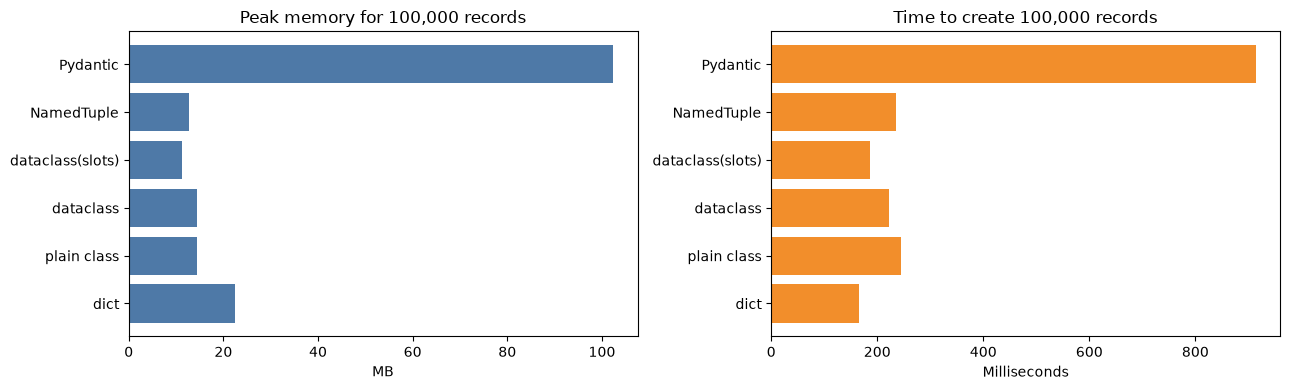

dict                22.4 MB    166.4 ms
plain class         14.4 MB    244.1 ms
dataclass           14.4 MB    222.8 ms
dataclass(slots)    11.2 MB    185.4 ms
NamedTuple          12.8 MB    235.8 ms
Pydantic           102.4 MB    913.9 ms


In [5]:
import time
import tracemalloc
from typing import NamedTuple

import matplotlib.pyplot as plt

class PlainClass:
    def __init__(self, a, b, c, d, e):
        self.a, self.b, self.c, self.d, self.e = a, b, c, d, e

@dataclass
class DC:
    a: int; b: int; c: float; d: str; e: bool

@dataclass(slots=True)
class DCSlots:
    a: int; b: int; c: float; d: str; e: bool

class NT(NamedTuple):
    a: int; b: int; c: float; d: str; e: bool

class PM(BaseModel):
    a: int; b: int; c: float; d: str; e: bool

makers = {
    "dict": lambda i: {"a": i, "b": i, "c": 1.0, "d": "x", "e": True},
    "plain class": lambda i: PlainClass(i, i, 1.0, "x", True),
    "dataclass": lambda i: DC(i, i, 1.0, "x", True),
    "dataclass(slots)": lambda i: DCSlots(i, i, 1.0, "x", True),
    "NamedTuple": lambda i: NT(i, i, 1.0, "x", True),
    "Pydantic": lambda i: PM(a=i, b=i, c=1.0, d="x", e=True),
}
n = 100_000
mem, speed = {}, {}
for name, make in makers.items():
    tracemalloc.start()
    t = time.perf_counter()
    objs = [make(i) for i in range(n)]
    speed[name] = (time.perf_counter() - t) * 1000
    mem[name] = tracemalloc.get_traced_memory()[1] / 1e6
    tracemalloc.stop()
    del objs

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.barh(list(mem), list(mem.values()), color="#4E79A7")
ax1.set(title=f"Peak memory for {n:,} records", xlabel="MB")
ax2.barh(list(speed), list(speed.values()), color="#F28E2B")
ax2.set(title=f"Time to create {n:,} records", xlabel="Milliseconds")
plt.tight_layout()
plt.show()
for name in makers:
    print(f"{name:<17} {mem[name]:6.1f} MB  {speed[name]:7.1f} ms")

`slots=True` and `NamedTuple` use the least memory because they do not store a per-object dictionary. Pydantic is slower to create because it validates every field; this is the price of safety, and it is small compared with a network request.

*Insight: Use a dataclass for data that your own code creates, and a Pydantic model at every boundary where data enters your system: API requests, configuration files, database rows from other teams and LLM outputs.*

## Real-World Use Case or Analogy

A dataclass is like a **printed form** with labelled boxes: it organises the information, but nobody checks what you write in the boxes. A Pydantic model is the **clerk at the counter** who reads the form, converts "three" to 3 when possible, and hands it back with every mistake marked.

FastAPI uses Pydantic models to validate every HTTP request (M30). Settings for services come from environment variables through `pydantic-settings`. LLM frameworks define the expected answer as a Pydantic model and validate the model output against it (M29).